# Análise exploratória: avaliações de clientes da Olist

O objetivo desta análise é decidir o que entra na base de conhecimento do RAG e
em que forma. Cada seção termina em uma regra que o Passo 3 aplica.

Os números e figuras vêm de `src/preparacao/exploracao.py`, que grava o resumo em
`reports/analise_exploratoria.json`.

In [1]:
import os, sys, re
sys.path.insert(0, os.path.abspath(".."))

import pandas as pd
from IPython.display import Image, display

from src.preparacao.carga import carregar_avaliacoes
from src.preparacao import exploracao as ex

bruto = carregar_avaliacoes()
resumo = ex.executar()
df = bruto.drop_duplicates("review_id")
print(f"{len(bruto):,} linhas no arquivo, {bruto.shape[1]} colunas".replace(",", "."))
bruto.head(3)

99.224 linhas no arquivo. 7 colunas


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17,2018-02-18 14:36:24


## 1. Unidade de análise

O arquivo tem uma linha por par avaliação-pedido. O mesmo `review_id` aparece em
pedidos diferentes quando o cliente avaliou uma compra que gerou mais de um
pedido; nesses casos a nota e o texto são idênticos.

In [2]:
pd.Series(resumo["volume"]).to_frame("valor")

,valor
linhas_no_arquivo,99224
review_id_unicos,98410
review_id_repetidos,789
linhas_removidas_na_deduplicacao,814
repetidos_com_nota_ou_texto_diferente,0
pedidos_com_mais_de_uma_avaliacao,547
periodo,"[2016-10-02, 2018-08-31]"


Nenhum dos 789 `review_id` repetidos tem nota ou texto diferente entre as cópias.
Contar cada cópia duplicaria a evidência: uma mesma reclamação apareceria duas
vezes no contexto e pesaria em dobro numa contagem de frequência.

**Regra:** uma avaliação por `review_id`.

## 2. Quem escreve comentário

Só 41,3% das avaliações têm comentário, e essa taxa depende muito da nota.

In [3]:
v = resumo["vies_de_selecao"]
pd.DataFrame({
    "com comentário (%)": v["pct_com_comentario_por_nota"],
    "notas, todas as avaliações (%)": v["distribuicao_notas_todas"],
    "notas, só as com comentário (%)": v["distribuicao_notas_com_comentario"],
}).rename_axis("nota")

,com comentário (%),"notas, todas as avaliações (%)","notas, só as com comentário (%)"
nota,,,
1,76.6,11.5,21.2
2,68.0,3.2,5.2
3,43.6,8.2,8.7
4,31.3,19.3,14.6
5,35.9,57.8,50.3


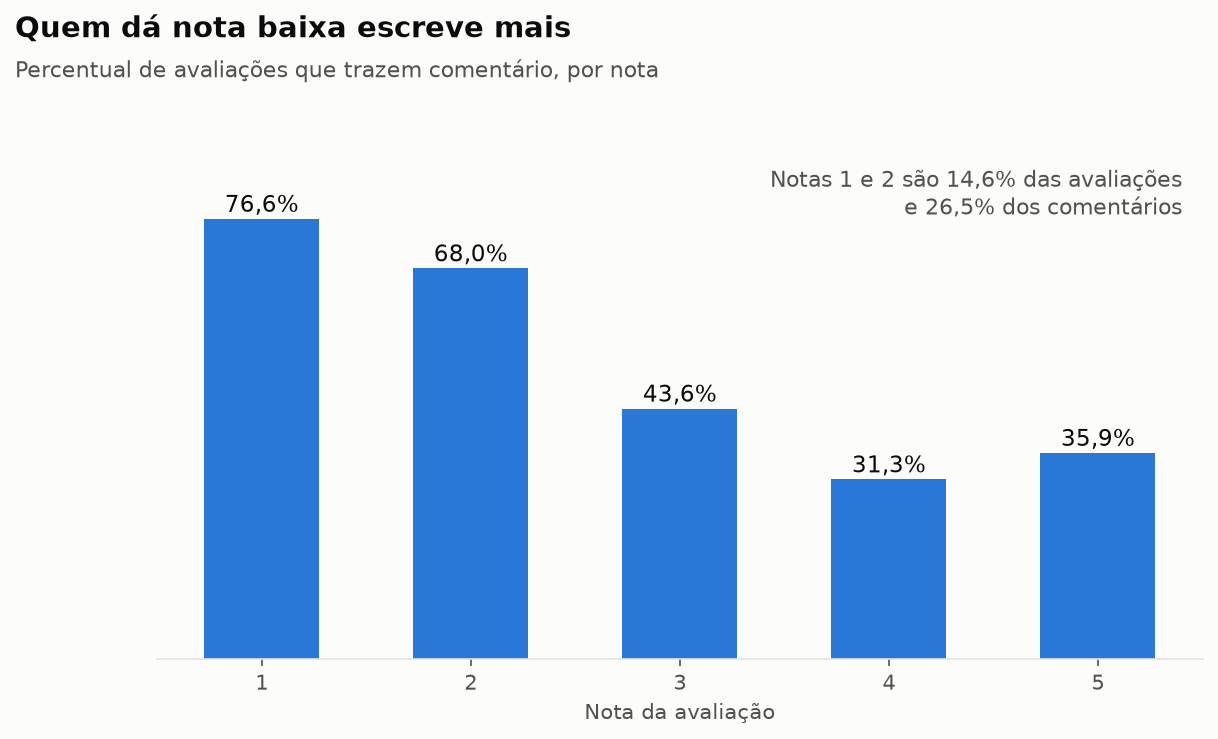

In [4]:
display(Image("../images/01_comentario_por_nota.png"))

Três em cada quatro clientes que dão nota 1 escrevem; entre os que dão nota 4,
menos de um em três. O resultado é que as notas 1 e 2 são 14,6% das avaliações e
26,5% dos comentários: na base de texto, a insatisfação aparece quase o dobro do
que aparece entre os clientes.

Isso não é um problema a corrigir, é uma característica a declarar. A base de
conhecimento representa **quem escreveu**, não todos os clientes.

**Regra:** respostas sobre frequência dizem que a proporção se refere aos
comentários, e nunca extrapolam para "os clientes da Olist".

## 3. Tamanho dos comentários

In [5]:
pd.Series(resumo["tamanho"]).to_frame("valor")

,valor
caracteres_mediana,53.0
caracteres_p90,161.0
caracteres_max,208.0
palavras_mediana,9.0
palavras_p90,28.0
exatamente_no_limite,654.0
a_ate_5_do_limite,1719.0
pct_a_ate_5_do_limite,4.2


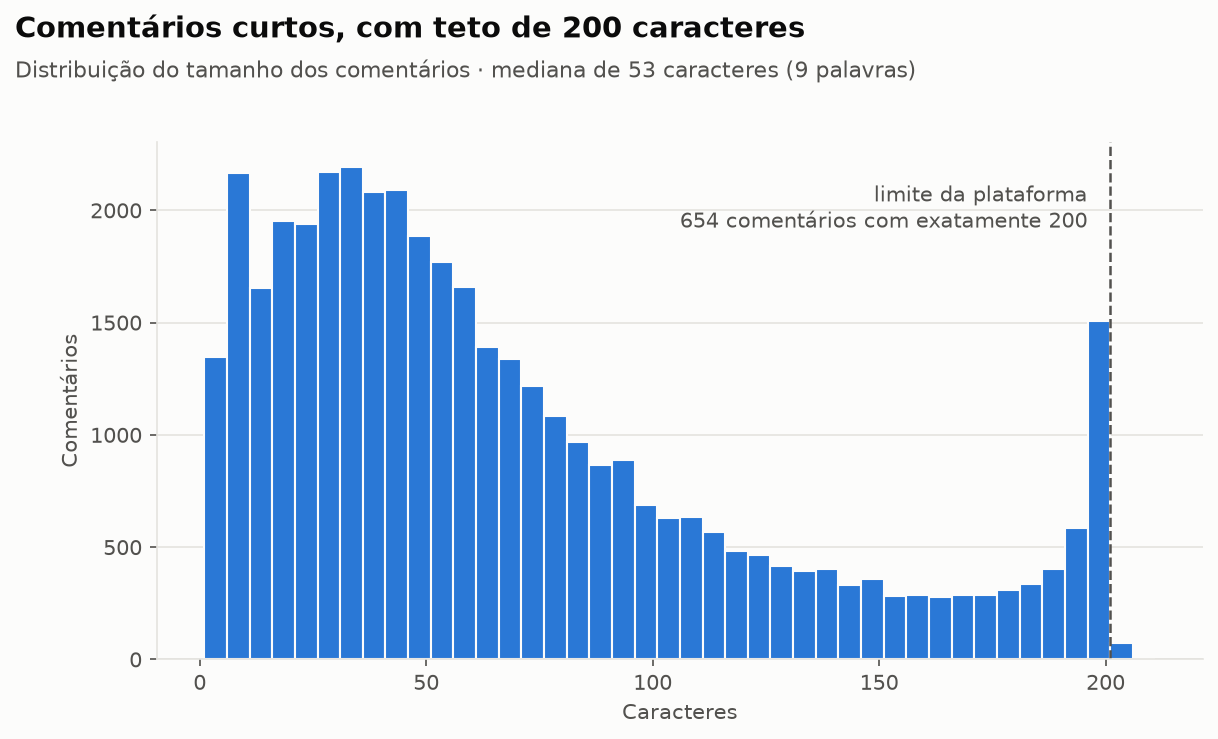

In [6]:
display(Image("../images/02_tamanho_comentarios.png"))

Os comentários são curtos (mediana de 53 caracteres) e acumulam em 200, o limite
da plataforma. Parte dos que chegam no limite foi cortada no meio da palavra:

In [7]:
coment = df["review_comment_message"].dropna()
for t in coment[coment.str.len() >= 199].head(5):
    print("...", t[-70:])

... te de Eva Nº Letras 36 Peças Crianças 1 un - R$ 35,90 (ESTE FOI ENTREG
... to via e-mail qto por telef.O suspense terminou mas lá não compro mais
...  No site das lannister costumam chegar antes do prazo. Estranhei muito
... de 50,00 reais ... um produto com defeito e até agora não me deu retor
... sa saio correndo. Um absurdo. Quase um mês para entregar. Extra.com ok


Com textos desse tamanho não faz sentido dividir em pedaços (*chunking*): o
comentário inteiro já cabe com folga no contexto, e dividir quebraria a ligação
entre a evidência e a avaliação de origem.

**Regra:** cada avaliação é um documento. Texto cortado no limite é mantido como
está; a interface mostra a evidência exatamente como o cliente escreveu.

## 4. Comentários que não dizem nada

Um RAG recupera evidência para perguntas como "o que os clientes mais elogiam?".
"Muito bom" responde que o cliente gostou, mas não do quê.

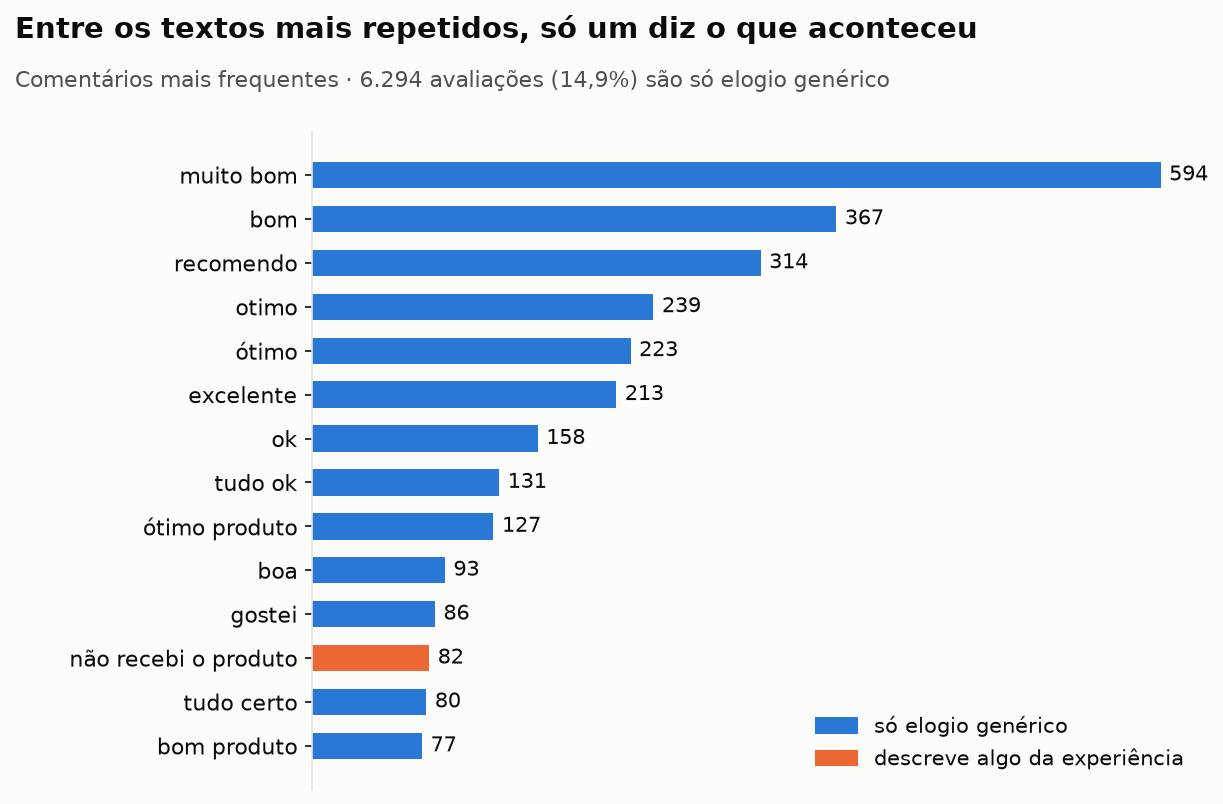

In [8]:
display(Image("../images/03_comentarios_mais_repetidos.png"))

In [9]:
pd.Series(resumo["informatividade"]).to_frame("valor")

,valor
avaliacoes_com_algum_texto,42293.00
so_elogio_generico,6294.00
pct_so_elogio_generico,14.90
nota_media_genericos,4.66
nota_media_demais,3.54
sem_nenhuma_palavra,42.00
previsao_base_de_conhecimento,35957.00


Para separar o que é genérico, a regra olha o **vocabulário**, não o tamanho.
Cortar por número de palavras eliminaria "não recebi" e "entrega rápida", que têm
duas palavras e estão entre as evidências mais úteis da base. A lista de palavras
genéricas está em `VOCAB_GENERICO` e é conservadora: na dúvida, o comentário fica.

In [10]:
texto = ex.texto_completo(df)
curtos = texto[texto.map(lambda t: 0 < len(ex.tokens(t)) <= 2)]
mantidos = curtos[~curtos.map(ex.eh_generico)].str.lower().value_counts().head(12)
excluidos = curtos[curtos.map(ex.eh_generico)].str.lower().value_counts().head(12)
pd.DataFrame({"mantido": mantidos.index, "excluído": excluidos.index})

,mantido,excluído
0,entrega rápida,muito bom
1,não recebi,bom
2,bom atendimento,recomendo
3,entrega rapida,ótimo
4,ótimo atendimento,otimo
5,ótimo vendedor,excelente
6,regular,super recomendo
7,excelente atendimento,ok
8,exelente,boa
9,otimo vendedor,tudo ok


**Regra:** saem as avaliações formadas só por elogio genérico (14,9% das que têm
texto, nota média 4,66) e as que não têm nenhuma palavra. A previsão é de
35.957 documentos na base de conhecimento.

Uma consequência: elogios genéricos são quase todos de clientes satisfeitos, então
excluí-los reduz ainda mais a parcela positiva da base. A pergunta "o que os
clientes elogiam?" continua respondível, porque os elogios com aspecto ("chegou
antes do prazo", "bem embalado") permanecem.

## 5. Ruído, dados pessoais e texto com cara de instrução

In [11]:
pd.DataFrame({
    "ocorrências": {**resumo["ruido"], **resumo["dados_pessoais"],
                    "termos de instrução": resumo["termos_de_instrucao"],
                    "lojas anonimizadas": resumo["lojas_anonimizadas"]}
})

,ocorrências
quebra_de_linha,3806
tudo_maiusculo,1096
letra_repetida_3x,256
emoji,288
e-mail,0
celular,2
link,2
CPF,0
termos de instrução,82
lojas anonimizadas,1951


**Quebras de linha** (3.806) viram espaço. **Caixa alta, letras repetidas e
emojis** ficam: o modelo de embeddings lida com eles, e um "PÉSSIMO 😡" carrega
intensidade que vale preservar na evidência mostrada ao usuário.

**Dados pessoais** são raros: 2 avaliações com celular pessoal e 2 com link,
nenhum e-mail ou CPF. O detector de celular exige DDD seguido de 9 e o de CPF
valida o dígito verificador, para não confundir com número de pedido ou data. Os
números não são exibidos aqui.

**Texto com cara de instrução:** 82 avaliações usam termos como "ignorar",
"instruções" ou "desconsiderar". Todas foram lidas: são pedidos de manual,
clientes dizendo que foram ignorados pelo vendedor e um pedido para
"desconsiderar a primeira avaliação". Nenhuma é tentativa de manipular um modelo,
mas o último caso mostra o risco: um texto legítimo de cliente, lido como
instrução, poderia mudar o comportamento do modelo.

In [12]:
inst = texto[texto.map(lambda t: bool(re.search(ex.TERMOS_INSTRUCAO, t, flags=re.I)))]
for t in inst.head(6):
    print("-", t[:120])

- Lindo... Só faltou instruções da troca de pulseiras
- Não realiza o que promete, depois de instalado fica vazando pelo cartucho, mesmo seguindo as instruções, não vale a pena
- Cartucho HP 60 colorido não funciona, impressora não reconhece como HP. Solicito instruções para devolução do produto e 
- Produto péssimo. Com emblema de ponta-cabeça (invertido) e contém avaria. Já fiz contato com a loja através do e-mail e 
- Transcorreu tudo bem. O vendedor não mandou instruções de cura
- O produto esquenta bastante, instruções para instalação em inglês, tive dificuldades na instalação


**Lojas anonimizadas:** 1.951 comentários citam nomes como "lannister", "stark" e
"targaryen". Na anonimização da base, os nomes das lojas foram trocados por casas
de Game of Thrones. Perguntas sobre uma loja pelo nome real não têm como ser
respondidas, e isso entra nas limitações.

**Regras:** quebra de linha vira espaço; celular e link são mascarados como
`[CELULAR]` e `[LINK]`; no prompt, as avaliações entram delimitadas e marcadas
como dado a ser analisado, nunca como instrução (Passo 6).

## 6. Do que os clientes falam

Uma estimativa por palavras-chave, independente do RAG. Ela é grosseira de
propósito, mas dá a ordem de grandeza de cada tema e servirá no Passo 8 para
conferir se as respostas sobre frequência fazem sentido.

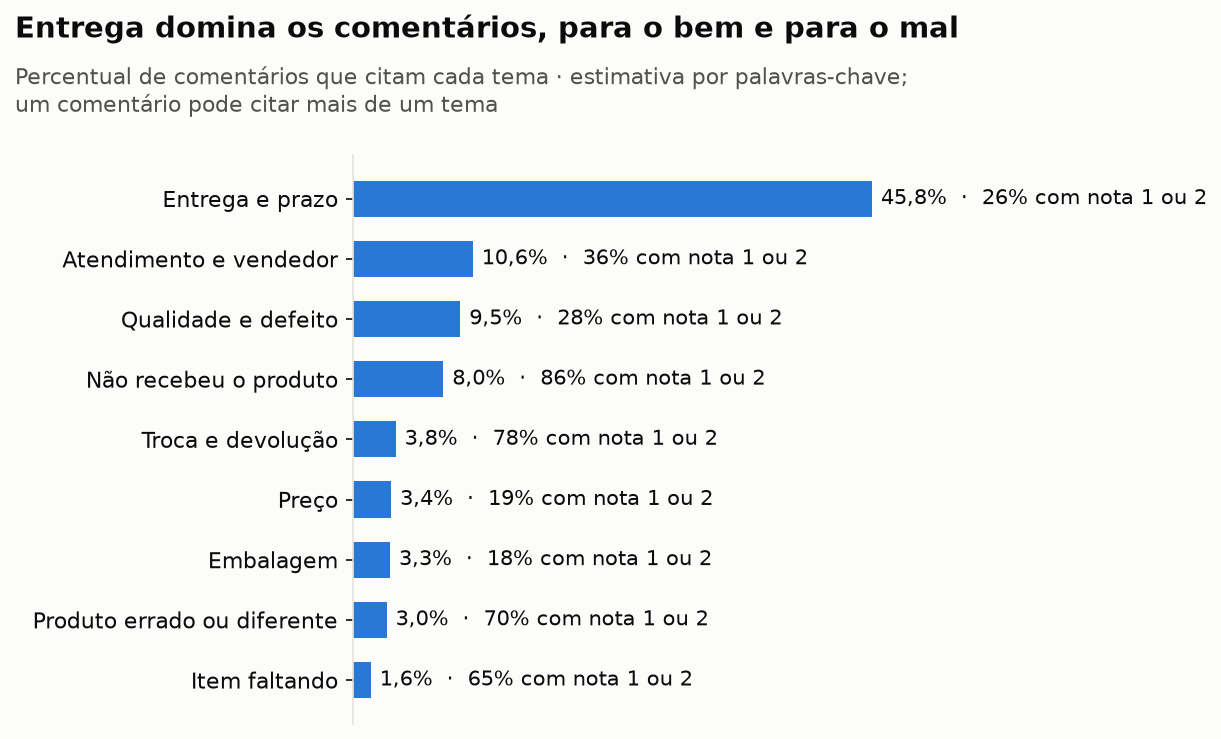

In [13]:
display(Image("../images/04_temas_por_palavra_chave.png"))

In [14]:
pd.DataFrame(resumo["temas_por_palavra_chave"]).T

,comentarios,pct_dos_comentarios,pct_com_nota_1_2
Entrega e prazo,18626.0,45.8,26.0
Atendimento e vendedor,4322.0,10.6,36.0
Qualidade e defeito,3856.0,9.5,28.0
Não recebeu o produto,3266.0,8.0,86.0
Troca e devolução,1531.0,3.8,78.0
Embalagem,1360.0,3.3,18.0
Produto errado ou diferente,1220.0,3.0,70.0
Preço,1372.0,3.4,19.0
Item faltando,653.0,1.6,65.0


Entrega aparece em quase metade dos comentários e só um quarto deles tem nota 1
ou 2: "chegou antes do prazo" é o elogio mais comum da base, e "não recebi" uma
das reclamações mais comuns. Um sistema que recupere "entrega" sem distinguir os
dois lados vai misturar elogio e reclamação na mesma resposta.

Os temas com maior proporção de notas baixas são não recebimento (86%), troca e
devolução (78%) e produto errado (70%). Embalagem e preço aparecem mais em
comentários positivos.

## 7. Decisões que a base de conhecimento herda

| Achado | Regra no Passo 3 |
|---|---|
| 789 `review_id` repetidos em pedidos diferentes, sempre com o mesmo texto | Uma avaliação por `review_id` |
| 56,9% das avaliações não têm título nem comentário | Entram só avaliações com algum texto |
| Título e comentário se complementam | Documento = título + comentário |
| 14,9% são só elogio genérico | Saem, por vocabulário e não por tamanho |
| Comentários de até ~200 caracteres | Uma avaliação = um documento, sem *chunking* |
| 3.806 comentários com quebra de linha | Quebra de linha vira espaço |
| 2 celulares pessoais e 2 links | Mascarados como `[CELULAR]` e `[LINK]` |
| Notas baixas super-representadas no texto | Respostas de frequência se referem aos comentários |
| Texto legítimo que soa como instrução | Avaliações entram no prompt como dado delimitado |